# Tuần 15 — Dự đoán (2/2): Quá khớp và hồi quy logistic

**UET.MAT1052 — Xác suất thống kê**

ThS. Hoàng Hữu Bách — BM. Khoa học & Kỹ thuật tính toán - Khoa Công nghệ Thông tin, VNU-UET

### Câu hỏi của buổi

Hai câu hỏi mở đầu:

1. Một đa thức bậc 12 đi gần như qua **mọi** điểm của 14 điểm dữ liệu. Nó có dự đoán tốt hơn một đường cong đơn giản không?
2. Trong một dây chuyền chỉ 2% sản phẩm bị lỗi, một mô hình **luôn** báo "không lỗi" đúng 98%. Nó có giúp phát hiện sản phẩm lỗi không?

Tuần 14 đã cảnh báo: $R^2$ và RSE tính trên chính dữ liệu đã khớp. Tuần này học cách đánh giá dự đoán **trung thực**: trên dữ liệu mô hình chưa thấy. Sau đó mở rộng dự đoán sang kết quả có/không bằng hồi quy logistic, và học những thước đo phân loại nhìn xa hơn tỉ lệ đúng.

### Sau buổi này, bạn làm được

- phân biệt sai số trong mẫu và ngoài mẫu; nhận diện thiếu khớp và quá khớp;
- dùng tách train/test và kiểm định chéo $k$-fold; giữ riêng tập kiểm tra cuối khỏi mọi bước lựa chọn;
- tính hàm sigmoid, odds, log-odds; diễn giải hệ số logistic như hệ số nhân của odds;
- lập ma trận nhầm lẫn và tính accuracy, precision, recall, F1; giải thích vì sao accuracy dễ gây hiểu lầm khi lớp mất cân bằng;
- chọn ngưỡng phân loại theo tiêu chí định trước và kiểm tra độ hiệu chỉnh (calibration) của xác suất.

Nội dung đáp ứng **LLO15.1/CLO4** của đề cương.

### Cần nhớ từ các buổi trước

- **$R^2$, RSE chỉ đo trong mẫu** (Tuần 14). Thêm biến luôn làm $R^2$ tăng; $R^2_{adj}$ phạt độ phức tạp nhưng vẫn là tiêu chí trong mẫu.
- **Biến Bernoulli** (Tuần 06). $Y\in\{0,1\}$, $P(Y=1)=p$, $E(Y)=p$.
- **Xác suất có điều kiện** (Tuần 05). $P(Y=1\mid X=x)$: xác suất kết quả 1 khi biết $x$.
- **Hàm mũ và logarit** (toán phổ thông). $e^{a+b}=e^ae^b$; $\ln$ là hàm ngược của $e^x$; $e^0=1$.
- **Sai lầm loại I và loại II** (Tuần 11). Báo động giả và bỏ sót có hậu quả khác nhau; chọn ngưỡng là chọn đánh đổi giữa chúng.

### Cách học notebook này

1. **Đọc** tình huống và phần giải tay.
2. **Đoán** kết quả trước khi chạy ô code hay mở đáp án.
3. **Chạy** ô bằng `Shift + Enter`.
4. **So sánh** kết quả với dự đoán; nếu khác, tìm xem mình đã hiểu sai ở bước nào.

Khối **Vì sao?** chứa chứng minh, có thể đọc sau. Ô có chú thích **Thử đổi** là chỗ bạn sửa tham số rồi chạy lại. Tên Ví dụ, Bài và Câu hỏi giữ đúng như slide để tiện đối chiếu.

**Thực hành vẽ:** [hướng dẫn Plotnine](./HUONG_DAN_PLOT.md). Mỗi hình có một đoạn “Đọc code vẽ” giải thích đúng các lệnh dùng ở hình đó, và một đoạn “Đọc hình” chỉ ra cần nhìn vào đâu.

## Lộ trình học

| Cách học | Nội dung cần làm |
|---|---|
| Học trên lớp | Mục 1–3: quá khớp, train/test và kiểm định chéo, hồi quy logistic. Mục 5: ma trận nhầm lẫn và các thước đo. |
| Tự luyện | Ví dụ 1–3, Bài tập 1–4: tự tính odds, xác suất, ma trận nhầm lẫn trước khi mở đáp án. |
| Đọc sâu | Mục 4 và 6 (bổ sung): quy trình train/validation/test đầy đủ, chọn ngưỡng, calibration; các khối **Vì sao?** về odds và F1. |

Chạy từ đầu bằng **Restart Kernel and Run All Cells** trước khi học, để mọi bảng và hình khớp với chữ trong bài.

### Đi đến các phần

[1. Mô hình có thể học cả nhiễu](#muc-1) · [2. Tập kiểm tra cuối phải đứng ngoài lựa chọn](#muc-2) · [3. Xác suất cho biến nhị phân: sigmoid và odds](#muc-3) · [4. Chia dữ liệu trước khi khớp và chọn ngưỡng](#muc-4) · [5. Ma trận nhầm lẫn và thước đo](#muc-5) · [6. Báo cáo cuối: xác suất, nhãn và calibration](#muc-6)

## Ký hiệu dùng trong buổi này

| Ký hiệu | Đọc là | Nghĩa | Ví dụ trong bài |
|---|---|---|---|
| RMSE | căn trung bình bình phương sai số | $\sqrt{\frac1m\sum(y_i-\hat y_i)^2}$ trên tập đang đánh giá, cùng đơn vị $y$ | bậc 3: 0,30 trên tập kiểm tra |
| train / validation / test | tập huấn luyện / kiểm định / kiểm tra | dùng để khớp hệ số / để chọn mô hình, ngưỡng / để báo cáo cuối cùng | 60% / 20% / 20% |
| fold | phần | một phần dữ liệu trong kiểm định chéo | 5-fold: 5 phần |
| $\eta$ | ê-ta | điểm tuyến tính $b_0+b_1x_1+\cdots$, chính là log-odds | $\eta=1-0{,}5x$ |
| $\hat p$ | p mũ | xác suất dự đoán của lớp 1, $1/(1+e^{-\eta})$ | $\eta=0\Rightarrow\hat p=0{,}5$ |
| odds | tỉ số chênh | $p/(1-p)$ | $p=0{,}8\Rightarrow$ odds $=4$ |
| $e^{b_j}$ | e mũ b j | hệ số nhân của odds khi $x_j$ tăng 1 đơn vị | $e^{0{,}244}\approx1{,}28$ |
| $t$ | ngưỡng | dự đoán lớp 1 nếu $\hat p\ge t$ | $t=0{,}5$ |
| TP, TN, FP, FN | dương thật, âm thật, dương giả, âm giả | bốn ô của ma trận nhầm lẫn | FN = bỏ sót ca lỗi |
| precision, recall, F1 | độ chính xác, độ phủ, F1 | trong số báo dương có bao nhiêu đúng; trong số dương thật bắt được bao nhiêu; trung bình điều hòa của hai cái | $20/22$; $20/50$ |

**Hai nghĩa của "kiểm tra".** Slide dùng "tập kiểm tra" cho mọi dữ liệu ngoài tập huấn luyện. Notebook tách rõ: **validation** là dữ liệu dùng để **chọn** (bậc đa thức, ngưỡng); **test cuối** là dữ liệu chỉ mở **sau khi** đã chọn xong. Lý do ở mục 2.

**Lớp 1.** Trong dữ liệu `qc`, lớp 1 là **đạt**. Trong các bài phát hiện lỗi, lớp 1 là **lỗi**. Đọc lại quy ước trước khi diễn giải TP hay FN.

### Thiết lập tính toán

- `numpy.polynomial.Polynomial.fit(x, y, bậc)`: khớp đa thức bằng bình phương tối thiểu; kết quả gọi được như một hàm, `poly(x)`.
- `smf.logit('dat ~ diem_do', data).fit()`: khớp hồi quy logistic; `scipy.special.expit` là hàm sigmoid $1/(1+e^{-x})$.
- Mọi dữ liệu tuần này là **mô phỏng** (đa thức, `qc`) hoặc số liệu cho sẵn của slide; chú thích ngay tại chỗ. Các ô mô phỏng có seed riêng để kết quả cố định.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

DATA = Path('datasets')
assert DATA.is_dir(), 'Hãy mở notebook từ thư mục có datasets/ đi kèm.'
rng = np.random.default_rng(42)
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 12)

from plotnine import (ggplot, aes, geom_histogram, geom_line, geom_point, geom_col,
    geom_vline, geom_hline, geom_segment, geom_area, geom_tile, geom_text,
    facet_wrap, labs, theme_minimal, theme, element_text, scale_color_manual,
    scale_fill_manual, coord_cartesian)

<a id="muc-1"></a>

## 1. Mô hình có thể học cả nhiễu

### Sai số trong mẫu và ngoài mẫu

- **Sai số trong mẫu** (in-sample, training error): đo trên chính dữ liệu đã dùng để khớp. Gần như luôn giảm khi mô hình phức tạp hơn.
- **Sai số ngoài mẫu** (out-of-sample, test error): đo trên dữ liệu mới mà mô hình chưa từng thấy. Đây mới là thước đo thật của khả năng dự đoán.

Mục tiêu của dự đoán là sai số **ngoài mẫu** thấp, không phải trong mẫu.

Thước đo dùng trong mục này là
$$\text{RMSE}=\sqrt{\frac1m\sum_{i=1}^m(y_i-\hat y_i)^2},$$
tính trên tập đang đánh giá (có $m$ điểm), cùng đơn vị với $y$.

### Thiếu khớp và quá khớp

- **Thiếu khớp** (underfitting): mô hình quá đơn giản, bỏ sót cấu trúc thật. Sai số cao **cả** trong lẫn ngoài mẫu.
- **Quá khớp** (overfitting): mô hình quá phức tạp, bám theo cả nhiễu ngẫu nhiên. Sai số trong mẫu rất nhỏ, sai số ngoài mẫu lớn.

Giữa hai thái cực là vùng "vừa đủ phức tạp". Một mô hình đủ linh hoạt có thể "học thuộc" cả nhiễu của dữ liệu huấn luyện: khớp gần hoàn hảo mà dự đoán tệ.

Với các đa thức khớp bằng bình phương tối thiểu trên **cùng** dữ liệu, tăng bậc không bao giờ làm sai số huấn luyện tăng (đa thức bậc cao chứa đa thức bậc thấp). Điều đó không nói gì về sai số ngoài mẫu.

### Ví dụ 1 — Sai số huấn luyện và sai số kiểm tra

Khớp đa thức bậc tăng dần lên cùng một bộ dữ liệu phi tuyến (14 điểm huấn luyện, 60 điểm kiểm tra riêng):

| Bậc | RMSE huấn luyện | RMSE kiểm tra |
|---|---:|---:|
| 1 | 0,52 | 0,58 |
| 3 | 0,25 | 0,30 |
| 12 | 0,01 | 18,81 |

Bậc nào thiếu khớp, bậc nào vừa phải, bậc nào quá khớp?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Bậc 1: thiếu khớp.* Đường thẳng bỏ sót độ cong của dữ liệu; sai số cao ở cả hai tập (0,52 và 0,58), hai con số gần nhau.

*Bậc 3: vừa phải.* Sai số kiểm tra thấp nhất (0,30): đủ linh hoạt để bắt xu hướng thật mà chưa bám nhiễu.

*Bậc 12: quá khớp.* RMSE huấn luyện gần 0 (0,01): đa thức gần như đi qua mọi điểm. Nhưng RMSE kiểm tra 18,81, lớn gấp hơn 60 lần bậc 3: giữa các điểm huấn luyện, đa thức dao động dữ dội.

*Bài học.* Không chọn mô hình vì sai số huấn luyện nhỏ (hay $R^2$ cao); phải nhìn sai số trên dữ liệu chưa thấy.

*Lưu ý.* Nếu dùng **chính cột kiểm tra này** để chọn bậc 3, thì tập 60 điểm đã tham gia lựa chọn: nó đóng vai **validation**. Con số 0,30 khi đó hơi lạc quan cho mô hình đã chọn; muốn báo sai số độc lập cần một tập dữ liệu mới (mục 2).

</details>

**Mô phỏng.** Slide không kèm dữ liệu và script vẽ, nên ô dưới dựng lại **cùng loại** thí nghiệm, không trùng số với bảng trên:

- dữ liệu thật: $y=\sin(\pi x)+$ nhiễu $\mathcal N(0;\ 0{,}22^2)$, $x\in[-1,1]$;
- 14 điểm huấn luyện, 60 điểm validation riêng;
- với mỗi bậc từ 1 đến 12: khớp trên 14 điểm, tính RMSE trên 14 điểm đó và trên 60 điểm validation.

**Bạn đoán trước:** cột `Train` có giảm đều theo bậc không? Cột `Validation` thì sao?

In [2]:
from numpy.polynomial import Polynomial
r_poly=np.random.default_rng(42)
x_train=np.sort(r_poly.uniform(-1,1,14))
y_train=np.sin(np.pi*x_train)+r_poly.normal(0,.22,len(x_train))
x_validation=np.linspace(-1,1,60)
y_validation=np.sin(np.pi*x_validation)+r_poly.normal(0,.22,60)
grid=np.linspace(-1,1,400)
curves=[]; error_rows=[]
for degree in range(1,13):
    poly=Polynomial.fit(x_train,y_train,degree)
    train_rmse=np.sqrt(np.mean((y_train-poly(x_train))**2))
    val_rmse=np.sqrt(np.mean((y_validation-poly(x_validation))**2))
    error_rows.append([degree,train_rmse,val_rmse])
    if degree in [1,3,12]:
        curves.append(pd.DataFrame({'x':grid,'prediction':poly(grid),'degree':str(degree)}))
poly_curves=pd.concat(curves,ignore_index=True)
poly_errors=pd.DataFrame(error_rows,columns=['degree','Train','Validation'])
error_long=poly_errors.melt(id_vars='degree',var_name='set',value_name='rmse')
display(poly_errors)
poly_points=pd.DataFrame({'x':x_train,'y':y_train})

,degree,Train,Validation
0,1,0.40843,0.50164
1,2,0.38866,0.53052
2,3,0.14534,0.17319
3,4,0.12661,0.29311
4,5,0.12661,0.29733
5,6,0.12373,0.43188
6,7,0.11975,0.76252
7,8,0.11855,0.23716
8,9,0.10299,25.12332
9,10,0.08409,171.20524


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `geom_line()` vẽ đường dự đoán của mỗi bậc từ bảng `ordered_curves`; `geom_point(poly_points, ..., inherit_aes=False)` thêm 14 điểm huấn luyện từ một bảng khác. `facet_wrap('~degree', scales='free_y')` tách ba bậc thành ba ô, mỗi ô có thang trục đứng riêng. `pd.Categorical(..., categories=['1','3','12'])` giữ thứ tự ô theo bậc.

**Đọc hình.** Bậc 1: đường thẳng cắt ngang, bỏ qua dạng sóng. Bậc 3: đường cong đi theo hình sin. Bậc 12: đường đi qua sát mọi chấm nhưng vọt lên hoặc tụt xuống rất xa ở giữa các chấm và ở hai đầu. Nhìn số trên trục đứng của ô bậc 12.

<!-- branch-plot-instructions: end -->

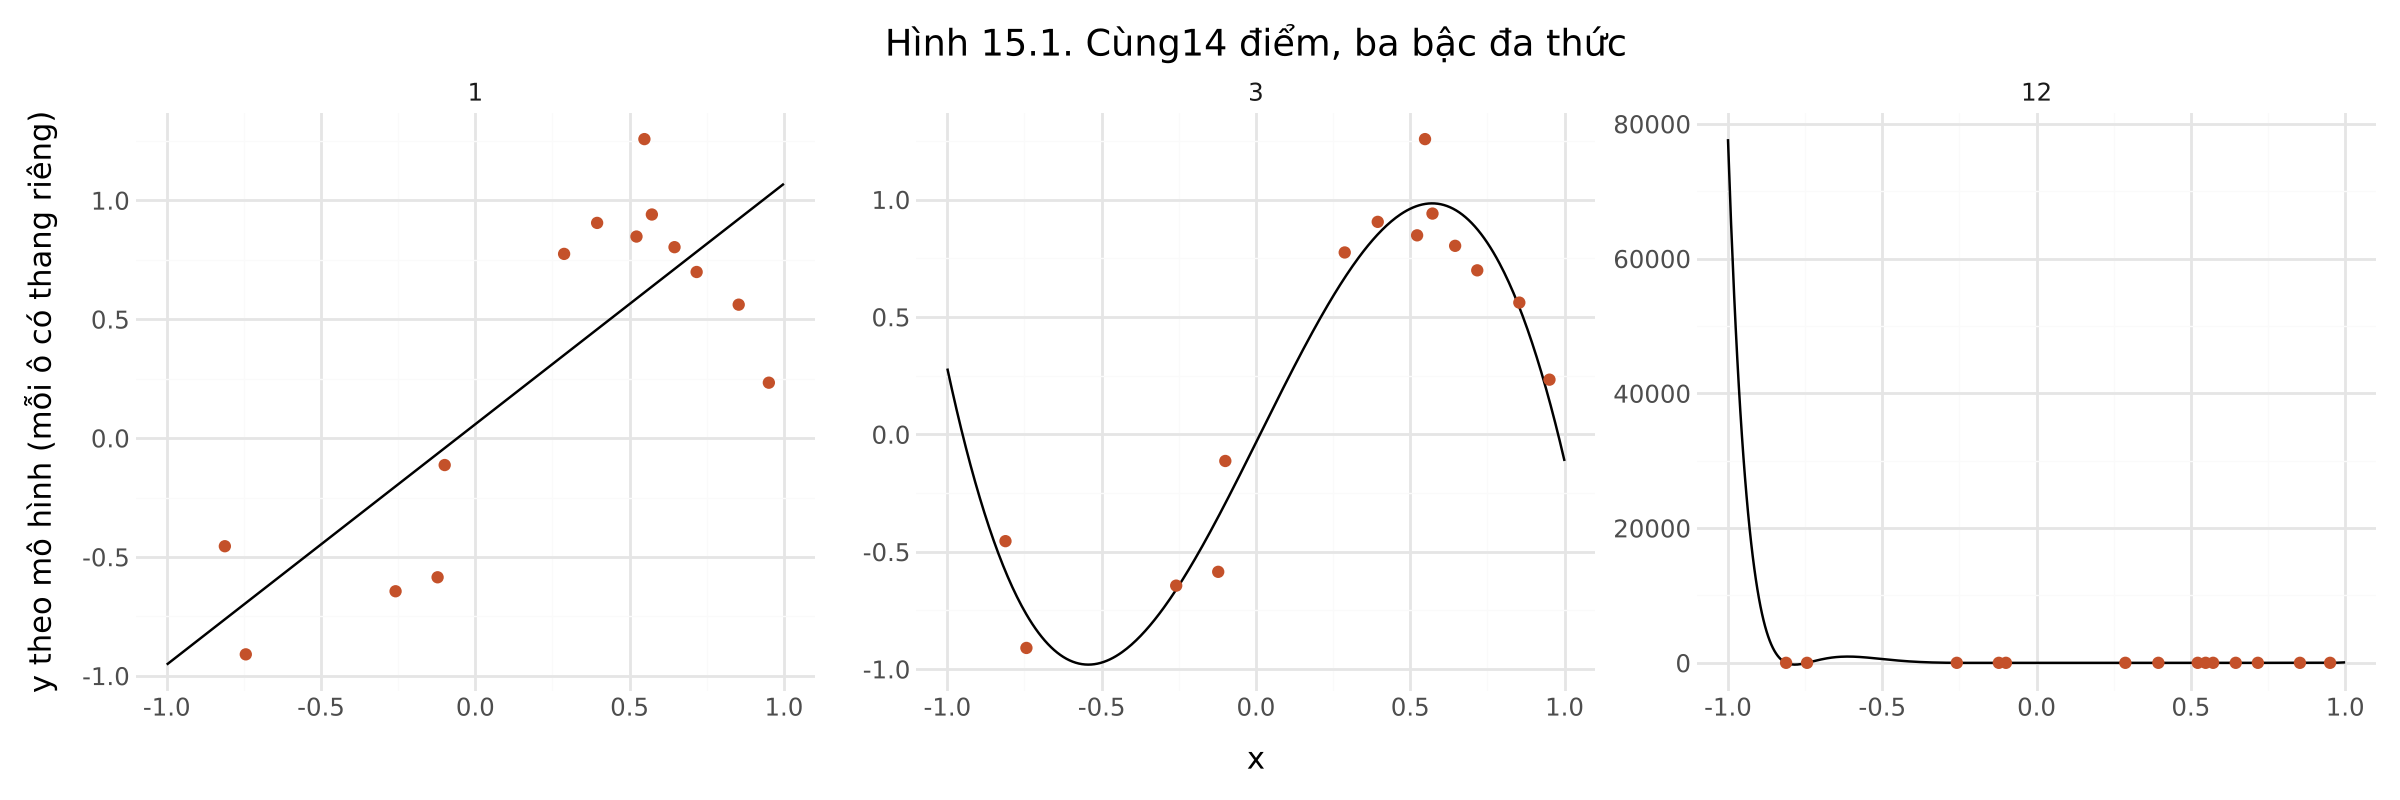

In [3]:
ordered_curves=poly_curves.assign(degree=pd.Categorical(poly_curves.degree,categories=['1','3','12'],ordered=True))
display(ggplot(ordered_curves,aes('x','prediction'))+geom_line()
    +geom_point(poly_points,aes('x','y'),inherit_aes=False,color='#C4512A')
    +facet_wrap('~degree',scales='free_y',ncol=3)
    +labs(title='Hình 15.1. Cùng14 điểm, ba bậc đa thức',x='x',y='y theo mô hình (mỗi ô có thang riêng)')
    +theme_minimal()+theme(figure_size=(12,4)))

Các ô dùng thang trục đứng riêng; nếu dùng chung thang với ô bậc 12, hai ô đầu sẽ chỉ còn là đường phẳng. So độ lớn sai số bằng bảng RMSE, cùng đơn vị.

**Bảng RMSE.** Cột `Train` giảm gần như đều từ 0,41 (bậc 1) xuống 0,07 (bậc 12). Cột `Validation` giảm đến bậc 3 (0,17), rồi dao động và tăng vọt từ bậc 9 (25), đến hàng nghìn ở bậc 12. Hình dưới vẽ hai cột này.

RMSE validation ở bậc cao lớn đến mức trục thường sẽ ép mọi giá trị nhỏ về sát 0, nên hình dưới dùng trục đứng **logarit**: mỗi vạch lớn gấp 10 lần vạch dưới; khoảng cách bằng nhau trên trục ứng với cùng một **tỉ số**, không phải cùng hiệu số.

<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(error_long, aes(...))` lấy bảng `error_long`; trong `aes`, trục ngang là cột `degree`, trục đứng là cột `rmse`. `color='set'` cho mỗi giá trị của cột `set` một màu riêng. `geom_line()` nối các điểm theo thứ tự tăng dần của trục ngang. `scale_y_log10()` đổi trục đứng sang thang log: mỗi vạch lớn gấp 10 lần vạch dưới, nhờ đó các giá trị rất nhỏ và rất lớn cùng nhìn thấy được.

**Đọc hình.** Đường `Train` đi xuống đều. Đường `Validation` đi xuống đến bậc 3 rồi tách hẳn khỏi đường `Train`; từ bậc 9 nó vọt lên nhiều bậc độ lớn. Khoảng cách giữa hai đường là dấu hiệu quá khớp.

<!-- branch-plot-instructions: end -->

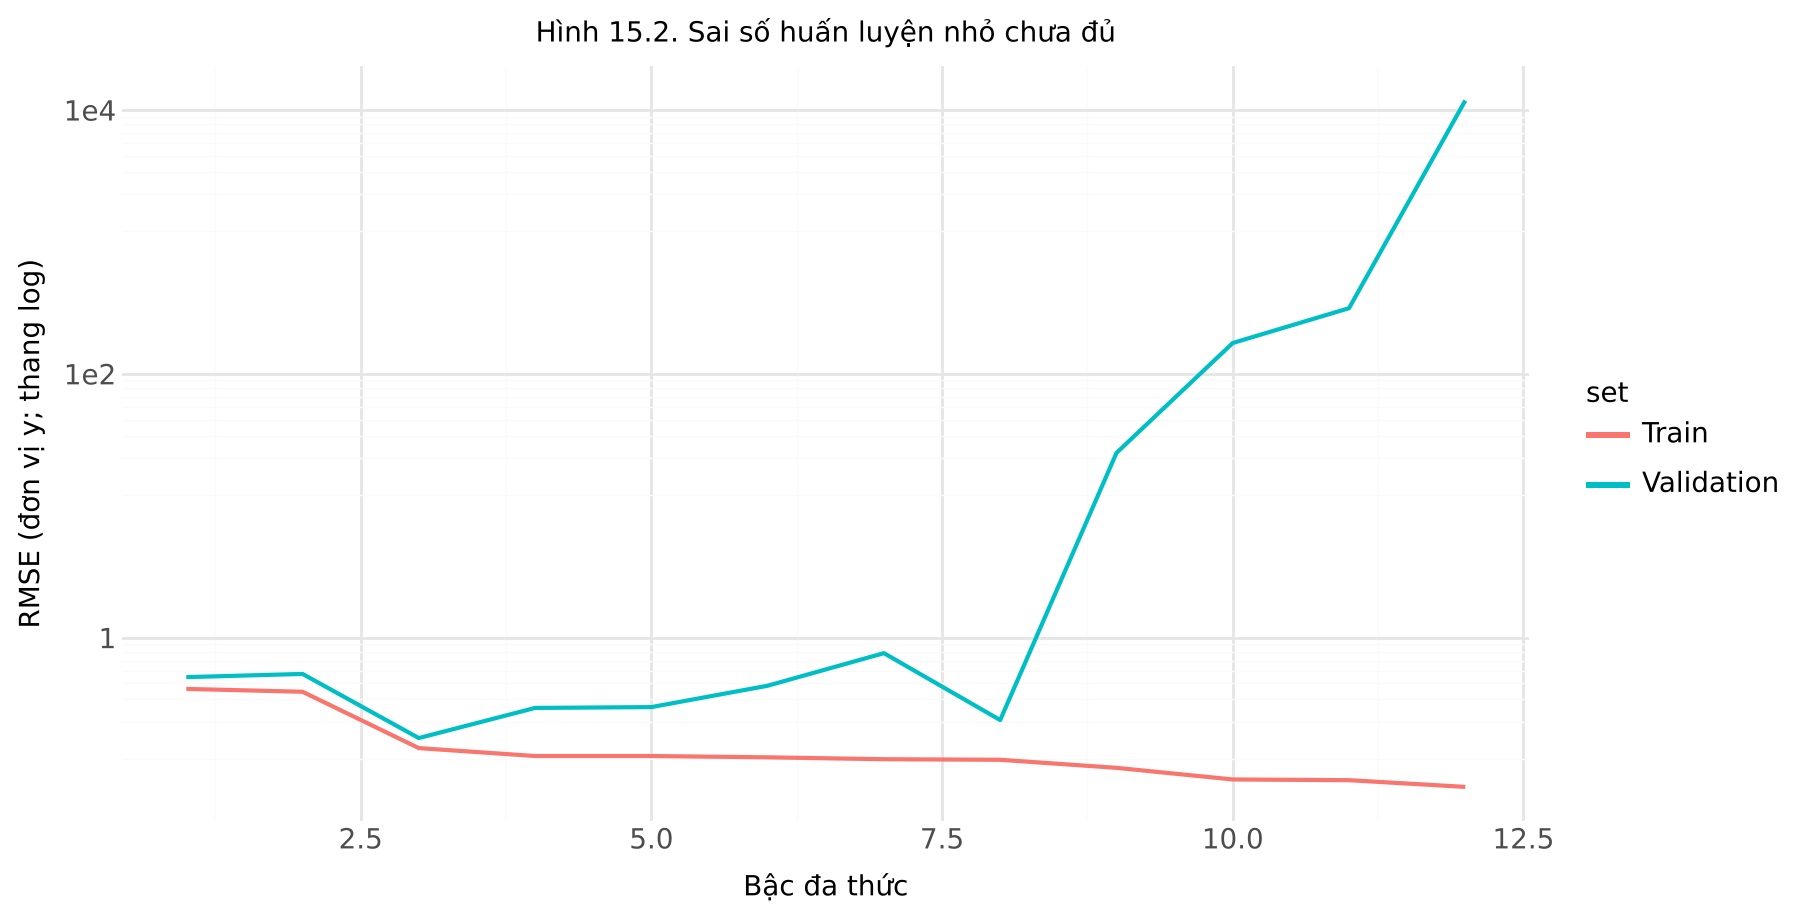

In [4]:
from plotnine import scale_y_log10
p = (ggplot(error_long, aes(x='degree', y='rmse', color='set'))
     + geom_line(size=0.85)
     + scale_y_log10()
     + labs(title='Hình 15.2. Sai số huấn luyện nhỏ chưa đủ', x='Bậc đa thức', y='RMSE (đơn vị y; thang log)')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Trên dữ liệu khác, điểm thấp nhất của đường validation có thể ở bậc khác. Không có quy tắc "luôn chọn bậc 3"; phải đo.

<a id="muc-2"></a>

## 2. Tập kiểm tra cuối phải đứng ngoài lựa chọn

### Chia train/test

Cách đơn giản nhất để ước lượng sai số ngoài mẫu: chia dữ liệu thành hai phần.

- **Tập huấn luyện** (training set): dùng để khớp mô hình (ước lượng hệ số).
- **Tập kiểm tra** (test set): giữ riêng, không dùng khi khớp, chỉ dùng để đo sai số dự đoán cuối cùng.

Tỉ lệ thường dùng: 70–80% huấn luyện, 20–30% kiểm tra, chia ngẫu nhiên. Nguyên tắc: mô hình **không được "nhìn thấy"** tập kiểm tra trong lúc huấn luyện hay chọn mô hình.

### Vì sao cần ba phần khi phải chọn

Nếu dùng tập kiểm tra để so nhiều ứng viên (nhiều bậc, nhiều ngưỡng) rồi chọn cái tốt nhất, thì con số của ứng viên thắng đã được "chọn lọc": nó hơi thấp hơn sai số thật trên dữ liệu mới. Vì vậy, khi có bước lựa chọn:

| Phần | Dùng để | Ví dụ |
|---|---|---|
| Huấn luyện | khớp hệ số | hệ số đa thức, hệ số logistic |
| Validation (hoặc kiểm định chéo trong tập huấn luyện) | **chọn**: bậc, biến, ngưỡng | bậc nào có RMSE validation thấp nhất |
| Test cuối | **báo cáo** sau khi đã chốt mọi lựa chọn | RMSE của mô hình đã chọn, đo đúng một lần |

Nếu đã xem kết quả test rồi quay lại sửa mô hình, tập test thành validation; phải thừa nhận điều đó, hoặc dùng dữ liệu mới.

### Kiểm định chéo $k$-fold

Một lần chia train/test có thể "may rủi". Kiểm định chéo dùng dữ liệu hiệu quả hơn:

1. Chia dữ liệu huấn luyện thành $k$ phần (fold) gần bằng nhau (thường $k=5$ hoặc $10$).
2. Lần lượt giữ **một** fold làm validation, khớp mô hình trên $k-1$ fold còn lại, đo sai số trên fold được giữ.
3. Lặp lại cho cả $k$ fold, rồi lấy trung bình $k$ sai số.

Mỗi quan sát được dùng để kiểm tra **đúng một lần**. Hai lưu ý:

- Mọi bước học từ dữ liệu (chuẩn hóa, điền giá trị thiếu, chọn biến) phải làm **bên trong** phần huấn luyện của từng fold; làm trên toàn bộ dữ liệu trước khi chia sẽ để lộ thông tin của fold validation.
- Dữ liệu có cấu trúc (nhiều dòng của cùng một người, dữ liệu theo thời gian) phải chia theo người hoặc theo thời gian, không xáo trộn từng dòng (cùng ý với Tuần 13).

### Liên hệ Tuần 14

$R^2_{adj}$ phạt việc thêm biến: đó là một cách **gần đúng, rẻ** để tránh quá khớp mà không cần tách dữ liệu. Train/test và kiểm định chéo đo **trực tiếp** sai số ngoài mẫu, nên đáng tin hơn.

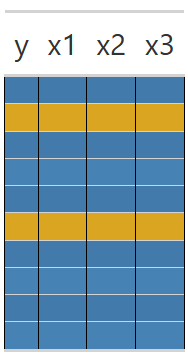

*Hình tham khảo 15.58: Tách tập huấn luyện và tập kiểm tra. Nguồn: STAT 20 bản dịch tiếng Việt, mục 7.4, hình nhúng trong học liệu gốc.*

Mỗi hàng là một quan sát; màu cho biết hàng đó thuộc tập huấn luyện hay tập kiểm tra. Nếu nhiều hàng thuộc cùng một người hay một thiết bị, phải giữ cả nhóm ở cùng một phía để thông tin không “rò” từ tập này sang tập kia.

Ô dưới lập bảng cho sơ đồ 5-fold của slide (trang 13): mỗi hàng là một lượt khớp, mỗi cột là một fold; `value = 1` nếu fold đó là validation ở lượt đó.

In [5]:
fold_design=pd.DataFrame([(iteration,fold,int(iteration==fold)) for iteration in range(1,6) for fold in range(1,6)],
    columns=['iteration','fold','value'])

<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(fold_design, aes(...))` lấy bảng `fold_design`; trong `aes`, trục ngang là cột `fold`, trục đứng là cột `iteration`. `geom_tile()` tô mỗi ô của lưới bằng màu theo cột `value`.

**Đọc hình.** Mỗi hàng là một lượt: đúng một ô đỏ (validation), bốn ô nhạt (huấn luyện). Các ô đỏ nằm trên đường chéo: mỗi fold làm validation đúng một lần qua 5 lượt.

<!-- branch-plot-instructions: end -->

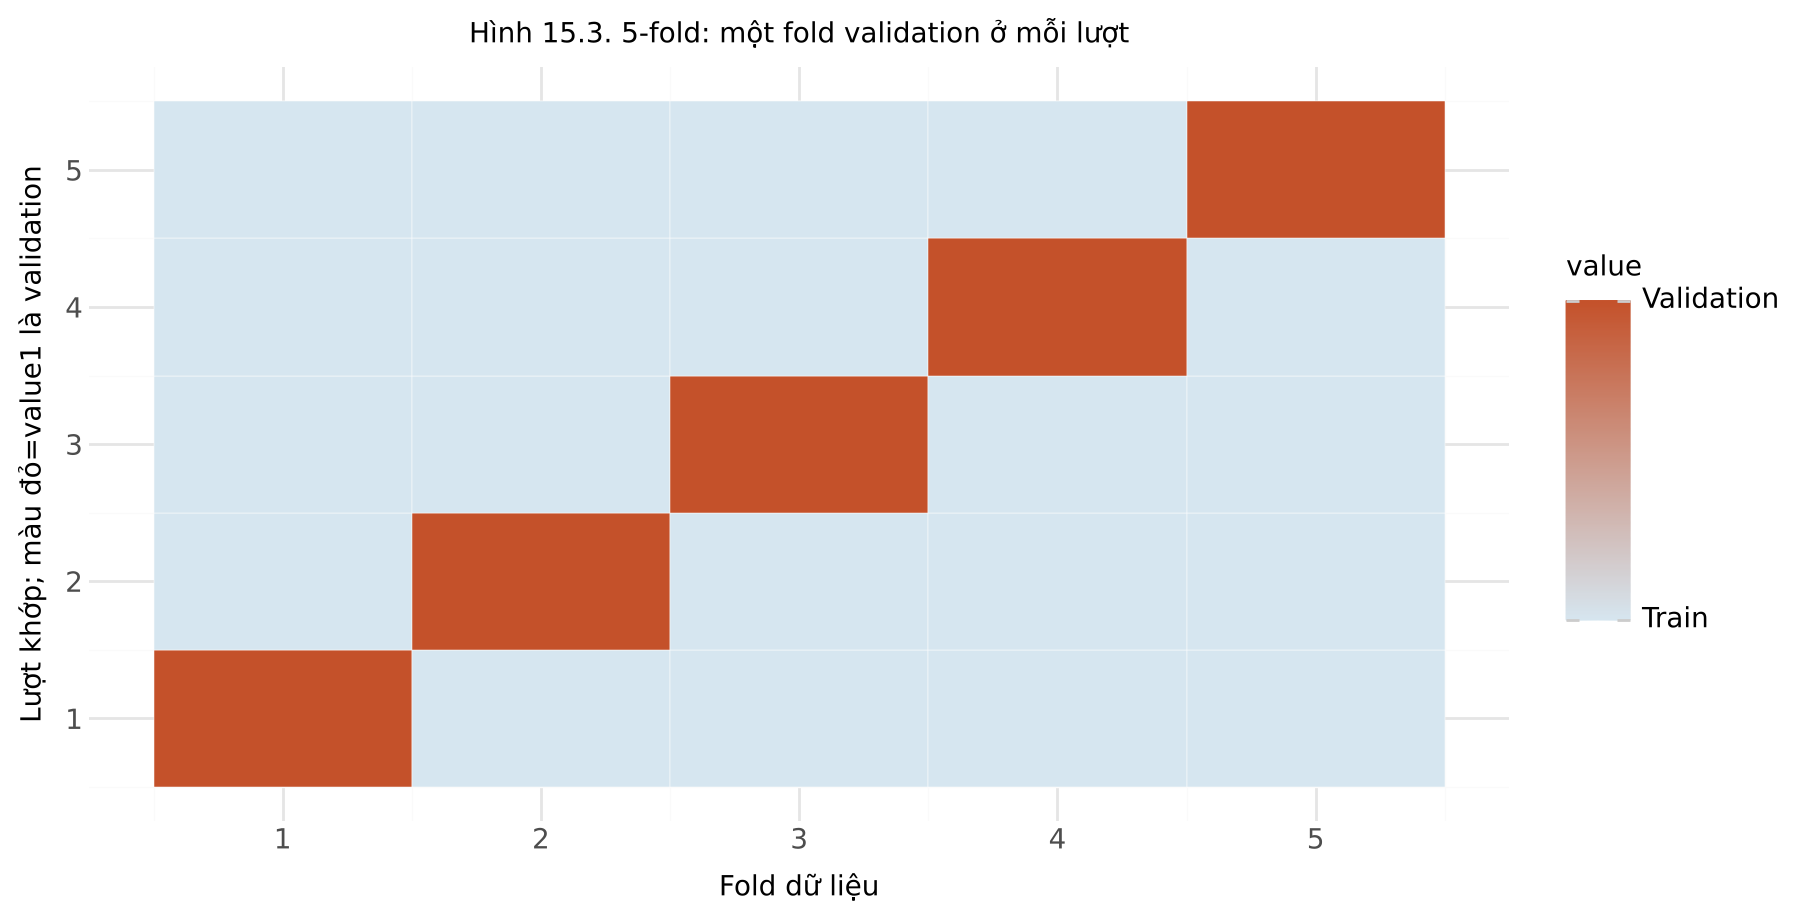

In [6]:
from plotnine import scale_fill_gradient
p = (ggplot(fold_design, aes(x='fold', y='iteration'))
     + geom_tile(aes(fill='value'), color='white')
     + scale_fill_gradient(low='#D6E6F0', high='#C4512A', breaks=[0,1], labels=['Train','Validation'])
     + labs(title='Hình 15.3. 5-fold: một fold validation ở mỗi lượt', x='Fold dữ liệu', y='Lượt khớp; màu đỏ=value1 là validation')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Ở mỗi lượt, ô đỏ **không** được dùng để khớp. Một lỗi hay gặp là khớp một lần trên cả 5 fold rồi mới chia dữ liệu khi tính sai số; làm vậy thì mọi điểm đều đã tham gia khớp và sai số đo được là sai số trong mẫu.

### Ví dụ 2 — Kiểm định chéo 5-fold

Đánh giá mô hình bậc 3 bằng 5-fold, RMSE trên từng fold:

| Fold | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| RMSE | 0,28 | 0,33 | 0,26 | 0,31 | 0,29 |

Tính RMSE trung bình. Con số này nói gì về sai số trên dữ liệu mới?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

$$\frac{0{,}28+0{,}33+0{,}26+0{,}31+0{,}29}5=\frac{1{,}47}5=0{,}294.$$

Slide gọi 0,294 là ước lượng ổn định cho sai số dự đoán trên dữ liệu mới, đáng tin hơn một lần chia đơn lẻ, vì nó gộp 5 lần đánh giá trên 5 phần dữ liệu khác nhau.

Nói chính xác hơn: đó là trung bình RMSE của **quy trình** "khớp bậc 3 trên 4/5 dữ liệu", vẫn là một ước lượng có sai số (các fold dao động từ 0,26 đến 0,33). Lấy trung bình 5 RMSE cũng không hoàn toàn bằng việc gộp tất cả sai số bình phương rồi lấy căn; khi báo cáo, nói rõ đã tính theo cách nào.

</details>

### Bài tập 1 — Chọn bậc đa thức theo sai số

Khớp đa thức bậc tăng dần, đo RMSE trên tập huấn luyện và tập kiểm tra:

| Bậc | RMSE huấn luyện | RMSE kiểm tra |
|---|---|---|
| 1 | 0,80 | 0,86 |
| 4 | 0,30 | 0,38 |
| 9 | 0,05 | 2,10 |

(a) Tính khoảng cách (RMSE kiểm tra − RMSE huấn luyện) cho mỗi bậc. (b) Bậc nào quá khớp? Nên triển khai bậc nào?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*(a)* Bậc 1: $0{,}86-0{,}80=0{,}06$. Bậc 4: $0{,}38-0{,}30=0{,}08$. Bậc 9: $2{,}10-0{,}05=2{,}05$.

*(b)* Bậc 9 quá khớp rõ: sai số huấn luyện gần 0 nhưng sai số kiểm tra lớn, khoảng cách 2,05. Nên triển khai **bậc 4**: RMSE kiểm tra thấp nhất (0,38). Chọn theo sai số ngoài mẫu, không theo sai số huấn luyện (nếu theo huấn luyện, ta sẽ chọn bậc 9).

Bậc 1 có khoảng cách nhỏ nhất nhưng sai số cao ở cả hai tập: thiếu khớp. Khoảng cách nhỏ chưa đủ; phải nhìn cả mức sai số.

Vì cột kiểm tra đã được dùng để chọn, nó đóng vai validation; con số 0,38 chưa phải sai số độc lập của mô hình đã chọn.

</details>

**Làm đầy đủ: chọn bằng kiểm định chéo, rồi mới mở test cuối.** Ô dưới làm đúng quy trình ba bước trên dữ liệu mô phỏng ở mục 1.

1. Định trước các ứng viên: bậc 1 đến 6. (Bậc 12 chỉ để minh họa quá khớp; với 14 điểm chia 5 fold, mỗi lượt chỉ khớp trên khoảng 11 điểm, không đủ cho bậc cao.)
2. 5-fold CV **trong 14 điểm huấn luyện**: `r_fold.permutation` xáo thứ tự, `np.array_split` chia thành 5 phần (3 hoặc 2 điểm mỗi phần). Với mỗi bậc và mỗi fold, khớp trên các điểm còn lại (`np.setdiff1d`), đo RMSE trên fold giữ lại.
3. Chọn bậc có RMSE CV trung bình thấp nhất, khớp lại trên cả 14 điểm.
4. **Chỉ sau đó** mới sinh và dùng 120 điểm test cuối (`x_final`, `y_final`), đo RMSE đúng một lần.

**Bạn đoán trước:** CV có chọn bậc 3, như bậc có RMSE validation thấp nhất ở bảng mục 1, không?

In [7]:
r_fold=np.random.default_rng(42)
permutation=r_fold.permutation(len(x_train))
folds=np.array_split(permutation,5)
cv_rows=[]
candidate_degrees=[1,2,3,4,5,6]
for degree in candidate_degrees:
    for fold_id,valid_idx in enumerate(folds,1):
        fit_idx=np.setdiff1d(np.arange(len(x_train)),valid_idx)
        fitted=Polynomial.fit(x_train[fit_idx],y_train[fit_idx],degree)
        rmse=np.sqrt(np.mean((y_train[valid_idx]-fitted(x_train[valid_idx]))**2))
        cv_rows.append([degree,fold_id,rmse])
cv=pd.DataFrame(cv_rows,columns=['degree','fold','rmse'])
cv_summary=cv.groupby('degree').rmse.agg(['mean','std'])
display(cv_summary)
selected_degree=int(cv_summary['mean'].idxmin())
selected_model=Polynomial.fit(x_train,y_train,selected_degree)
# Chỉ mở tập test cuối sau khi chốt bậc, không dùng để đổi bậc.
r_final=np.random.default_rng(20261117)
x_final=r_final.uniform(-1,1,120)
y_final=np.sin(np.pi*x_final)+r_final.normal(0,.22,len(x_final))
final_rmse=np.sqrt(np.mean((y_final-selected_model(x_final))**2))
print('Đã chốt bậc:',selected_degree,'; test cuối một lần RMSE=',final_rmse)
print('Ví dụ2 tính tay:',np.mean([.28,.33,.26,.31,.29]))
assert len(cv)==len(candidate_degrees)*5

,mean,std
degree,,
1,0.47352,0.09204
2,0.55412,0.13058
3,0.21750,0.08857
4,0.20337,0.11267
5,0.21279,0.12041
6,0.35938,0.20497


Đã chốt bậc: 4 ; test cuối một lần RMSE= 0.27840462715514264
Ví dụ2 tính tay: 0.29400000000000004


**Kết quả.** RMSE CV trung bình: bậc 3 khoảng 0,218, bậc 4 khoảng 0,203, bậc 5 khoảng 0,213: ba bậc rất gần nhau, và độ lệch chuẩn giữa các fold (cột `std`, khoảng 0,09–0,12) lớn hơn nhiều so với chênh lệch giữa chúng. CV chọn **bậc 4**; bảng validation ở mục 1 lại thấp nhất ở bậc 3. Với chỉ 14 điểm, hai cách đánh giá cho thứ hạng hơi khác nhau là bình thường. Test cuối cho RMSE khoảng 0,28.

Bậc 4 được chọn **chỉ** dựa vào CV, không dựa vào `y_final`. Nếu sau khi thấy 0,28 ta đổi sang bậc khác, thì 120 điểm kia đã thành validation và cần dữ liệu mới để báo cáo.

<a id="muc-3"></a>

## 3. Xác suất cho biến nhị phân: sigmoid và odds

### Vấn đề

Đạt/không đạt, lỗi/không lỗi, dương tính/âm tính: biến kết quả chỉ nhận 0 hoặc 1. Nếu dùng thẳng hồi quy tuyến tính $\hat y=b_0+b_1x$ để dự đoán "xác suất đạt", giá trị dự đoán có thể **nhỏ hơn 0 hoặc lớn hơn 1**, vô nghĩa với xác suất. Cần một hàm luôn cho giá trị trong $(0,1)$.

### Hàm sigmoid

$$\hat p(x)=\frac1{1+e^{-\eta}},\qquad \eta=b_0+b_1x_1+\cdots+b_px_p.$$
Đọc là: tính điểm tuyến tính $\eta$ như hồi quy thường, rồi "nén" nó vào khoảng $(0,1)$. Khi $\eta$ rất âm, $e^{-\eta}$ rất lớn nên $\hat p\approx0$; khi $\eta=0$, $\hat p=1/2$; khi $\eta$ rất dương, $\hat p\approx1$.

$\hat p(x)$ được diễn giải là **xác suất dự đoán của kết quả 1**, cho trước các biến $x$.

### Odds và log-odds

$$\text{odds}=\frac{\hat p}{1-\hat p}=e^{\eta},\qquad \log(\text{odds})=\eta=b_0+b_1x_1+\cdots.$$
**Odds** (tỉ số chênh) là xác suất xảy ra chia xác suất không xảy ra. Ví dụ $\hat p=0{,}8$ cho odds $=0{,}8/0{,}2=4$ ("4 ăn 1"). Odds khác xác suất: $p=0{,}5$ ứng với odds $=1$.

Phần tuyến tính của hồi quy logistic là **log-odds**, không phải xác suất. Hệ quả quan trọng:

> Tăng $x_j$ thêm 1 đơn vị (giữ các biến khác cố định) làm odds **nhân** với $e^{b_j}$, không phải cộng $b_j$ vào xác suất.

Mức thay đổi của **xác suất** khi $x_j$ tăng 1 đơn vị phụ thuộc vào xác suất đang ở đâu: lớn nhất quanh $\hat p=0{,}5$, nhỏ dần khi $\hat p$ gần 0 hoặc 1.
<details><summary><b>Vì sao?</b> sigmoid và log-odds là hai hàm ngược nhau; odds nhân $e^{b_j}$</summary>

*Từ sigmoid sang log-odds.* Từ $\hat p=1/(1+e^{-\eta})$ có $1-\hat p=e^{-\eta}/(1+e^{-\eta})$, nên
$$\frac{\hat p}{1-\hat p}=\frac1{e^{-\eta}}=e^{\eta},\qquad \log\frac{\hat p}{1-\hat p}=\eta.$$

*Odds nhân $e^{b_j}$.* So hai điểm chỉ khác nhau ở $x_j$ và $x_j+1$:
$$\frac{\text{odds}(x_j+1)}{\text{odds}(x_j)}=\frac{e^{\eta+b_j}}{e^{\eta}}=e^{b_j}.\ \blacksquare$$
Tỉ số này không phụ thuộc $x$: đó là lý do hệ số logistic được báo cáo dưới dạng **tỉ số odds** (odds ratio) $e^{b_j}$.

*Vì sao xác suất không thay đổi đều?* Đạo hàm của sigmoid là $\frac{d\hat p}{d\eta}=\hat p(1-\hat p)$, lớn nhất bằng $0{,}25$ tại $\hat p=0{,}5$. Gần 0 hoặc 1, cùng một thay đổi của $\eta$ chỉ làm $\hat p$ nhích rất ít.

</details>

### Khớp mô hình và điều kiện

Hệ số **không** tính bằng công thức OLS. Chúng được chọn để **cực đại hóa khả năng** (likelihood) của dữ liệu dưới mô hình Bernoulli, tương đương với tối thiểu hóa hàm mất mát log-loss; phần mềm làm việc này bằng thuật toán lặp, cùng tinh thần với gradient descent ở Tuần 14.

Điều kiện áp dụng:

- **Quan sát độc lập**: kết quả của một quan sát không phụ thuộc quan sát khác; cẩn thận khi nhiều lần đo trên cùng một đối tượng.
- **Tuyến tính với log-odds**: mỗi biến dự đoán có quan hệ tuyến tính với $\log(\text{odds})$, giữ các biến khác cố định; không phải tuyến tính với $\hat p$.

Nếu một ngưỡng của $x$ tách **hoàn toàn** hai lớp (mọi điểm dưới ngưỡng là 0, mọi điểm trên là 1), hệ số tiến ra vô cực và thuật toán không hội tụ; phần mềm thường cảnh báo, cần đọc cảnh báo thay vì chỉ lấy số.

### Ví dụ 3 — Kiểm soát chất lượng

Dữ liệu `qc`: `diem_do` là điểm đo một chỉ số vận hành, `dat` là đạt (1) hay không đạt (0). Khớp `smf.logit('dat ~ diem_do', data=qc).fit()` cho hệ số của `diem_do` là $b_1\approx0{,}244$. Khi điểm đo tăng 1 đơn vị, odds của việc đạt thay đổi thế nào?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

$$e^{0{,}244}\approx1{,}276.$$
Mỗi khi điểm đo tăng thêm 1 đơn vị, **odds** của việc đạt nhân khoảng 1,28, tức tăng khoảng 28%.

*Không được nói:* "xác suất đạt tăng 0,244" hay "tăng 24,4 điểm phần trăm". Ví dụ, nếu ở một điểm đo nào đó $\hat p=0{,}5$ (odds 1), thì ở điểm đo lớn hơn 1 đơn vị odds là 1,276, nên $\hat p=1{,}276/2{,}276\approx0{,}561$: xác suất tăng 6,1 điểm phần trăm. Nếu xuất phát từ $\hat p=0{,}9$ (odds 9), odds mới là 11,49 và $\hat p\approx0{,}920$: chỉ tăng 2 điểm phần trăm.

Đây là liên hệ theo mô hình trên dữ liệu quan sát, không tự là tác động khi chủ động tăng điểm đo.

</details>

### Bài tập 2 — Hệ số logistic và xác suất dự đoán

Mô hình logistic dự đoán “có nguy cơ lỗi” theo nhiệt độ vận hành $x$: $\log(\text{odds})=b_0+b_1x$ với $b_0=1{,}0$, $b_1=-0{,}5$. (a) Tính $e^{b_1}$ và diễn giải tác động của việc tăng nhiệt độ thêm 1 đơn vị lên odds. (b) Tính xác suất dự đoán $\hat p$ tại $x=2$. (c) Với ngưỡng 0,5 (quy tắc $\hat p\ge0{,}5$ là lớp 1), quan sát tại $x=2$ được phân vào lớp nào?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*(a)* $e^{-0{,}5}\approx0{,}607$. Mỗi khi nhiệt độ tăng 1 đơn vị, odds của "có nguy cơ lỗi" nhân với khoảng 0,61, tức **giảm** khoảng 39%. Vì $b_1<0$, nguy cơ giảm khi nhiệt độ tăng.

*(b)* Tại $x=2$: $\eta=1{,}0-0{,}5\times2=0$, nên
$$\hat p=\frac1{1+e^{-0}}=\frac1{1+1}=0{,}5.$$

*(c)* $\hat p=0{,}5\ge0{,}5$: phân vào **lớp 1** ("có nguy cơ lỗi"), đúng ngay tại ngưỡng. Nếu quy tắc là $\hat p>0{,}5$ thì sẽ ra lớp 0; vì vậy phải nói rõ quy tắc.

Mức giảm 39% là của **odds**, giống nhau ở mọi $x$. Xác suất không giảm 39% đều ở mọi mức nhiệt độ.

</details>

Ô dưới kiểm tra Ví dụ 3 và Bài tập 2, rồi **dựng dữ liệu mô phỏng** `qc` cho phần còn lại của buổi (slide không kèm dữ liệu gốc): 500 quan sát, điểm đo đều trên $[30,90]$, nhãn `dat` sinh từ mô hình logistic với $\eta=-14{,}64+0{,}244\cdot\text{diem\_do}$. `r_qc.binomial(1, p)` tung đồng xu có xác suất $p$ cho mỗi quan sát.

In [8]:
from scipy.special import expit
print('Ví dụ3: odds ratio=',np.exp(.244))
eta=1-.5*2
print('Bài2:',np.exp(-.5),expit(eta),int(expit(eta)>=.5))
assert expit(0)==.5
# Chưa có điểm gốc qc: tạo dữ liệu giả định cùng hình dạng, ghi rõ.
r_qc=np.random.default_rng(42)
qc=pd.DataFrame({'diem_do':r_qc.uniform(30,90,500)})
qc['dat']=r_qc.binomial(1,expit(-14.64+.244*qc.diem_do))
display(qc.head());print('Số mỗi lớp:',qc.dat.value_counts().to_dict())

Ví dụ3: odds ratio= 1.2763443304894546
Bài2: 0.6065306597126334 0.5 1


,diem_do,dat
0,76.43736,1
1,56.33271,1
2,81.51588,1
3,71.84208,1
4,35.65064,0


Số mỗi lớp: {1: 254, 0: 246}


Dữ liệu `qc` này là **mô phỏng**, không phải bộ gốc của slide hay số đo sản xuất. Quy tắc sinh có hệ số 0,244; hệ số khớp từ một mẫu sẽ gần nhưng không đúng bằng 0,244. Hai lớp gần cân bằng (254 đạt, 246 không đạt). Trong `qc`, lớp 1 là **đạt**.

<a id="muc-4"></a>

## 4. Chia dữ liệu trước khi khớp và chọn ngưỡng

Phần này **bổ sung**: làm trọn quy trình ở mục 2 cho hồi quy logistic.

1. **Chia trước, khớp sau.** Chia `qc` thành train 60%, validation 20%, test 20%, **phân tầng theo nhãn** (chia riêng trong lớp 0 và lớp 1) để ba phần giữ cùng tỉ lệ đạt. Với dữ liệu thật có nhiều phép đo trên một thiết bị, phải chia theo mã thiết bị.
2. **Khớp chỉ trên train.**
3. **Validation** dùng để chọn ngưỡng (mục 5).
4. **Test** giữ kín đến mục 6.

Ô dưới cũng khớp thêm một đường hồi quy tuyến tính thường cho `dat` trên train, để thấy nó dự đoán ra ngoài $[0,1]$.

In [9]:
r_split=np.random.default_rng(42)
train_idx=[];valid_idx=[];test_idx=[]
for label in [0,1]:
    ids=r_split.permutation(qc.index[qc.dat==label])
    a=int(.6*len(ids)); c=int(.8*len(ids))
    train_idx.extend(ids[:a]);valid_idx.extend(ids[a:c]);test_idx.extend(ids[c:])
train=qc.loc[train_idx].copy();valid=qc.loc[valid_idx].copy();test=qc.loc[test_idx].copy()
assert not(set(train_idx)&set(test_idx) or set(train_idx)&set(valid_idx) or set(valid_idx)&set(test_idx))
logit=smf.logit('dat ~ diem_do',train).fit(disp=False)
assert logit.mle_retvals['converged']
print('n train/validation/test:',len(train),len(valid),len(test))
print('Hệ số khớp train:',logit.params.to_dict())
print('Odds ratio khớp:',np.exp(logit.params['diem_do']))
grid_qc=pd.DataFrame({'diem_do':np.linspace(20,100,400)})
grid_qc['probability']=logit.predict(grid_qc)
linear_prob=smf.ols('dat ~ diem_do',train).fit()
print('OLS dự đoán ở điểm20/100:',linear_prob.predict(pd.DataFrame({'diem_do':[20,100]})).to_list())
probability_valid=logit.predict(valid).to_numpy()

n train/validation/test: 299 100 101
Hệ số khớp train: {'Intercept': -14.685647462485358, 'diem_do': 0.24369558302982294}
Odds ratio khớp: 1.2759558487486817
OLS dự đoán ở điểm20/100: [-0.4450638058825022, 1.4522463031685866]


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `geom_line()` vẽ đường sigmoid từ bảng `grid_qc` (400 điểm đo cách đều và xác suất dự đoán); `geom_point(train, aes('diem_do', 'dat'), inherit_aes=False, alpha=.3)` thêm các quan sát train ở độ cao 0 hoặc 1, trong suốt để thấy chỗ dày đặc.

**Đọc hình.** Các chấm chỉ nằm trên hai đường ngang $y=0$ và $y=1$. Bên trái hầu hết là 0, bên phải hầu hết là 1; vùng giữa (khoảng 50–70) có cả hai. Đường sigmoid đi từ gần 0 lên gần 1, qua 0,5 ở khoảng điểm đo 60 ($\eta=0$).

<!-- branch-plot-instructions: end -->

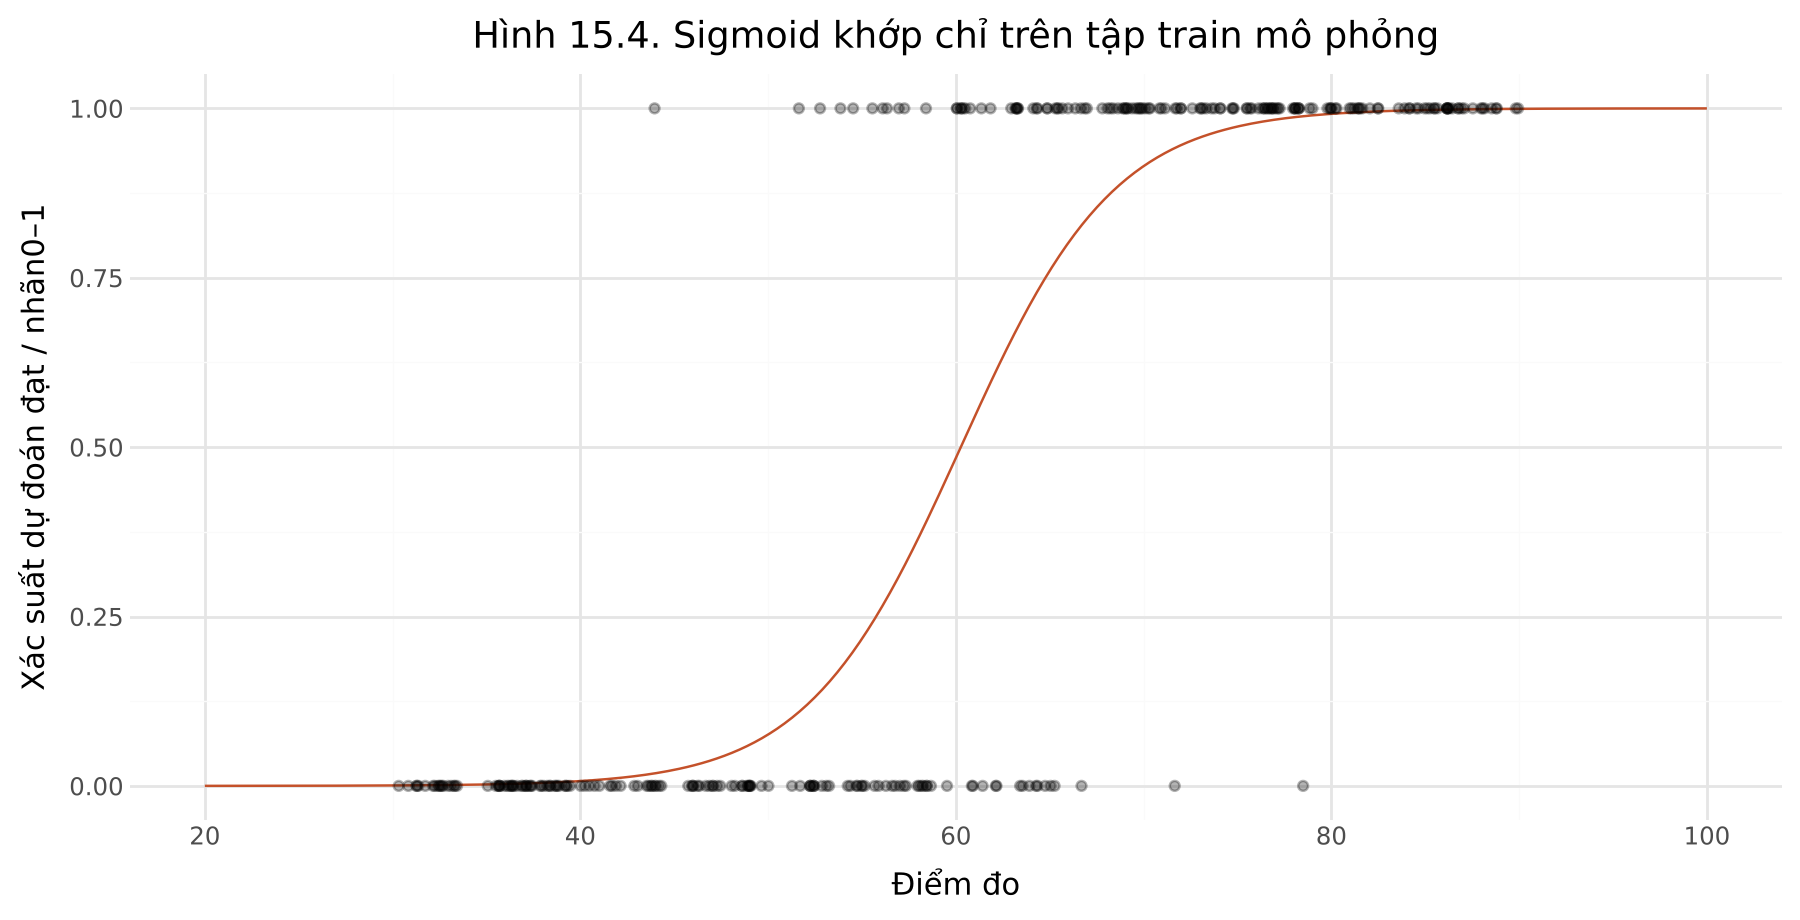

In [10]:
display(ggplot(grid_qc,aes('diem_do','probability'))+geom_line(color='#C4512A')
    +geom_point(train,aes('diem_do','dat'),inherit_aes=False,alpha=.3)
    +labs(title='Hình 15.4. Sigmoid khớp chỉ trên tập train mô phỏng',x='Điểm đo',y='Xác suất dự đoán đạt / nhãn0–1')
    +theme_minimal()+theme(figure_size=(9,4.6)))

**Kết quả.** 299 / 100 / 101 quan sát. Hệ số khớp trên train là 0,2437, odds ratio 1,276, rất gần quy tắc sinh. Đường hồi quy tuyến tính thường dự đoán $-0{,}45$ ở điểm đo 20 và $1{,}45$ ở điểm đo 100: ra ngoài $[0,1]$, đúng vấn đề nêu ở mục 3.

Sigmoid giải quyết chuyện **miền giá trị**. Còn xác suất của nó có khớp với tỉ lệ thực tế không (calibration) và nhãn dự đoán có tốt không là những câu hỏi phải đánh giá riêng, ở mục 5–6.

<a id="muc-5"></a>

## 5. Ma trận nhầm lẫn và thước đo

### Tình huống: accuracy cao trên dữ liệu mất cân bằng

Trong một dây chuyền, chỉ 2% sản phẩm thực sự lỗi. Một mô hình **luôn** dự đoán "không lỗi" (bất kể đầu vào) đúng với 98% sản phẩm. Nó có hữu ích không? Để trả lời cần nhìn chi tiết hơn một con số tỉ lệ đúng.

### Ngưỡng phân loại

Logistic cho **xác suất**. Muốn có **nhãn**, chọn ngưỡng $t$: dự đoán lớp 1 nếu $\hat p\ge t$, lớp 0 nếu ngược lại. Ngưỡng 0,5 là quy ước phổ biến, không bắt buộc. **Hạ ngưỡng** thì bắt được nhiều ca dương thật hơn nhưng cũng nhiều báo động giả hơn.

### Ma trận nhầm lẫn

Hàng là thực tế, cột là dự đoán:

| | Dự đoán 0 | Dự đoán 1 |
|---|---|---|
| **Thực tế 0** | TN (âm thật) | FP (dương giả, báo động giả) |
| **Thực tế 1** | FN (âm giả, bỏ sót) | TP (dương thật) |

"1" thường là lớp cần phát hiện (sản phẩm lỗi, bệnh dương tính). FN và FP thường có chi phí rất khác nhau.

### Bốn thước đo

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\qquad \text{Precision}=\frac{TP}{TP+FP},\qquad \text{Recall}=\frac{TP}{TP+FN},$$
$$F_1=\frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}=\frac{2TP}{2TP+FP+FN}.$$

| Thước đo | Câu hỏi |
|---|---|
| Accuracy | tỉ lệ dự đoán đúng trên tổng số; dễ gây hiểu lầm khi hai lớp mất cân bằng |
| Precision | trong các ca **được báo** là 1, bao nhiêu phần đúng là 1? |
| Recall | trong các ca **thực sự** là 1, mô hình bắt được bao nhiêu phần? |
| $F_1$ | trung bình điều hòa của precision và recall; chỉ cao khi cả hai cùng cao |

Nếu mô hình không báo dương ca nào ($TP+FP=0$), precision không xác định; phải nói rõ quy ước, không ghi là "hoàn hảo".

**Quay lại tình huống 2% lỗi.** Mô hình luôn báo "không lỗi": accuracy $=98\%$ nhưng $TP=0$, nên recall $=0$: không phát hiện được sản phẩm lỗi nào. Accuracy cao không có nghĩa mô hình hữu ích; khi lớp mất cân bằng, luôn xem thêm recall và precision, và so với mô hình "đoán lớp đa số" như một mốc.

### Chọn thước đo theo chi phí sai lầm

- Chẩn đoán bệnh, phát hiện lỗi an toàn: ưu tiên **recall** cao (không bỏ sót), chấp nhận một số báo động giả.
- Báo động giả rất tốn kém (dừng cả dây chuyền khi báo sai): ưu tiên **precision** cao.

Không có thước đo nào "đúng nhất" trong mọi bối cảnh.
<details><summary><b>Vì sao?</b> $F_1$ là trung bình điều hòa</summary>

Trung bình điều hòa của $P$ và $R$ là $\frac{2}{1/P+1/R}=\frac{2PR}{P+R}$. Thay $P=\frac{TP}{TP+FP}$, $R=\frac{TP}{TP+FN}$:
$$\frac1P+\frac1R=\frac{TP+FP}{TP}+\frac{TP+FN}{TP}=\frac{2TP+FP+FN}{TP},\qquad F_1=\frac{2TP}{2TP+FP+FN}.\ \blacksquare$$
Trung bình điều hòa bị kéo về phía số nhỏ hơn: $P=1$, $R=0{,}1$ cho $F_1\approx0{,}18$, trong khi trung bình cộng là 0,55. Vì vậy $F_1$ không "che" được một recall rất thấp. $F_1$ không chứa $TN$: nó không quan tâm mô hình làm tốt đến đâu ở lớp 0.

</details>

### Bài tập 3 — Tính bốn thước đo từ ma trận nhầm lẫn

Một mô hình phân loại cho $TP=6$, $TN=6$, $FP=2$, $FN=2$. Tính Accuracy, Precision, Recall (và đối chiếu $F_1$). Thước đo nào sẽ “lạc quan” nhất nếu lớp mất cân bằng như ví dụ dây chuyền 2% lỗi?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

$$\text{Accuracy}=\frac{6+6}{16}=0{,}75,\qquad \text{Precision}=\frac6{6+2}=0{,}75,\qquad \text{Recall}=\frac6{6+2}=0{,}75,\qquad F_1=\frac{12}{12+2+2}=0{,}75.$$
Ma trận này cân bằng (8 ca thật mỗi lớp, sai số đối xứng) nên cả bốn trùng nhau.

Khi lớp mất cân bằng như dây chuyền 2% lỗi, **accuracy** là thước đo lạc quan giả tạo nhất: mô hình luôn đoán lớp đa số vẫn đạt accuracy cao dù recall bằng 0.

</details>

Ô dưới viết hàm `classification_metrics(y_true, probability, threshold)`: đổi xác suất thành nhãn theo quy tắc $\hat p\ge t$, đếm bốn ô, rồi tính bốn thước đo (trả về `nan` khi mẫu số bằng 0). Sau đó áp hàm cho **validation** với 19 ngưỡng từ 0,05 đến 0,95, và chọn ngưỡng có $F_1$ lớn nhất. Tiêu chí "$F_1$ lớn nhất trên validation, nếu hòa thì lấy ngưỡng thấp hơn" được **định trước** khi nhìn bảng.

In [11]:
def classification_metrics(y_true,probability,threshold):
    y_true=np.asarray(y_true,dtype=int)
    predicted=np.asarray(probability)>=threshold
    tp=int(((y_true==1)&predicted).sum()); tn=int(((y_true==0)&~predicted).sum())
    fp=int(((y_true==0)&predicted).sum()); fn=int(((y_true==1)&~predicted).sum())
    precision=tp/(tp+fp) if tp+fp else np.nan
    recall=tp/(tp+fn) if tp+fn else np.nan
    f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan
    return {'threshold':threshold,'TP':tp,'TN':tn,'FP':fp,'FN':fn,
            'accuracy':(tp+tn)/len(y_true),'precision':precision,'recall':recall,'F1':f1}
threshold_rows=[classification_metrics(valid.dat,probability_valid,t) for t in np.linspace(.05,.95,19)]
threshold_table=pd.DataFrame(threshold_rows)
display(threshold_table)
threshold_long=threshold_table.melt(id_vars='threshold',value_vars=['precision','recall'],var_name='metric',value_name='value')
# Chọn F1 lớn nhất trên validation; nếu hòa,chọn ngưỡng thấp hơn.
selected_threshold=float(threshold_table.sort_values(['F1','threshold'],ascending=[False,True]).iloc[0].threshold)
print('Chốt ngưỡng theo F1 validation:',selected_threshold)

,threshold,TP,TN,FP,FN,accuracy,precision,recall,F1
0,0.05,51,33,16,0,0.84,0.76119,1.00000,0.86441
1,0.10,50,36,13,1,0.86,0.79365,0.98039,0.87719
2,0.15,49,40,9,2,0.89,0.84483,0.96078,0.89908
3,0.20,49,40,9,2,0.89,0.84483,0.96078,0.89908
4,0.25,48,41,8,3,0.89,0.85714,0.94118,0.89720
5,0.30,48,43,6,3,0.91,0.88889,0.94118,0.91429
6,0.35,48,45,4,3,0.93,0.92308,0.94118,0.93204
7,0.40,47,46,3,4,0.93,0.94000,0.92157,0.93069
8,0.45,46,46,3,5,0.92,0.93878,0.90196,0.92000
9,0.50,45,47,2,6,0.92,0.95745,0.88235,0.91837


Chốt ngưỡng theo F1 validation: 0.35


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(threshold_long, aes(...))` lấy bảng `threshold_long`; trong `aes`, trục ngang là cột `threshold`, trục đứng là cột `value`. `color='metric'` cho mỗi giá trị của cột `metric` một màu riêng. `geom_line()` nối các điểm theo thứ tự tăng dần của trục ngang.

**Đọc hình.** Đọc từ phải sang trái (hạ ngưỡng): đường recall đi lên đến 1 ở ngưỡng 0,05; đường precision nhìn chung đi xuống, từ khoảng 0,97 xuống 0,76. Hai đường cắt nhau quanh ngưỡng 0,35–0,40, gần chỗ $F_1$ lớn nhất.

<!-- branch-plot-instructions: end -->

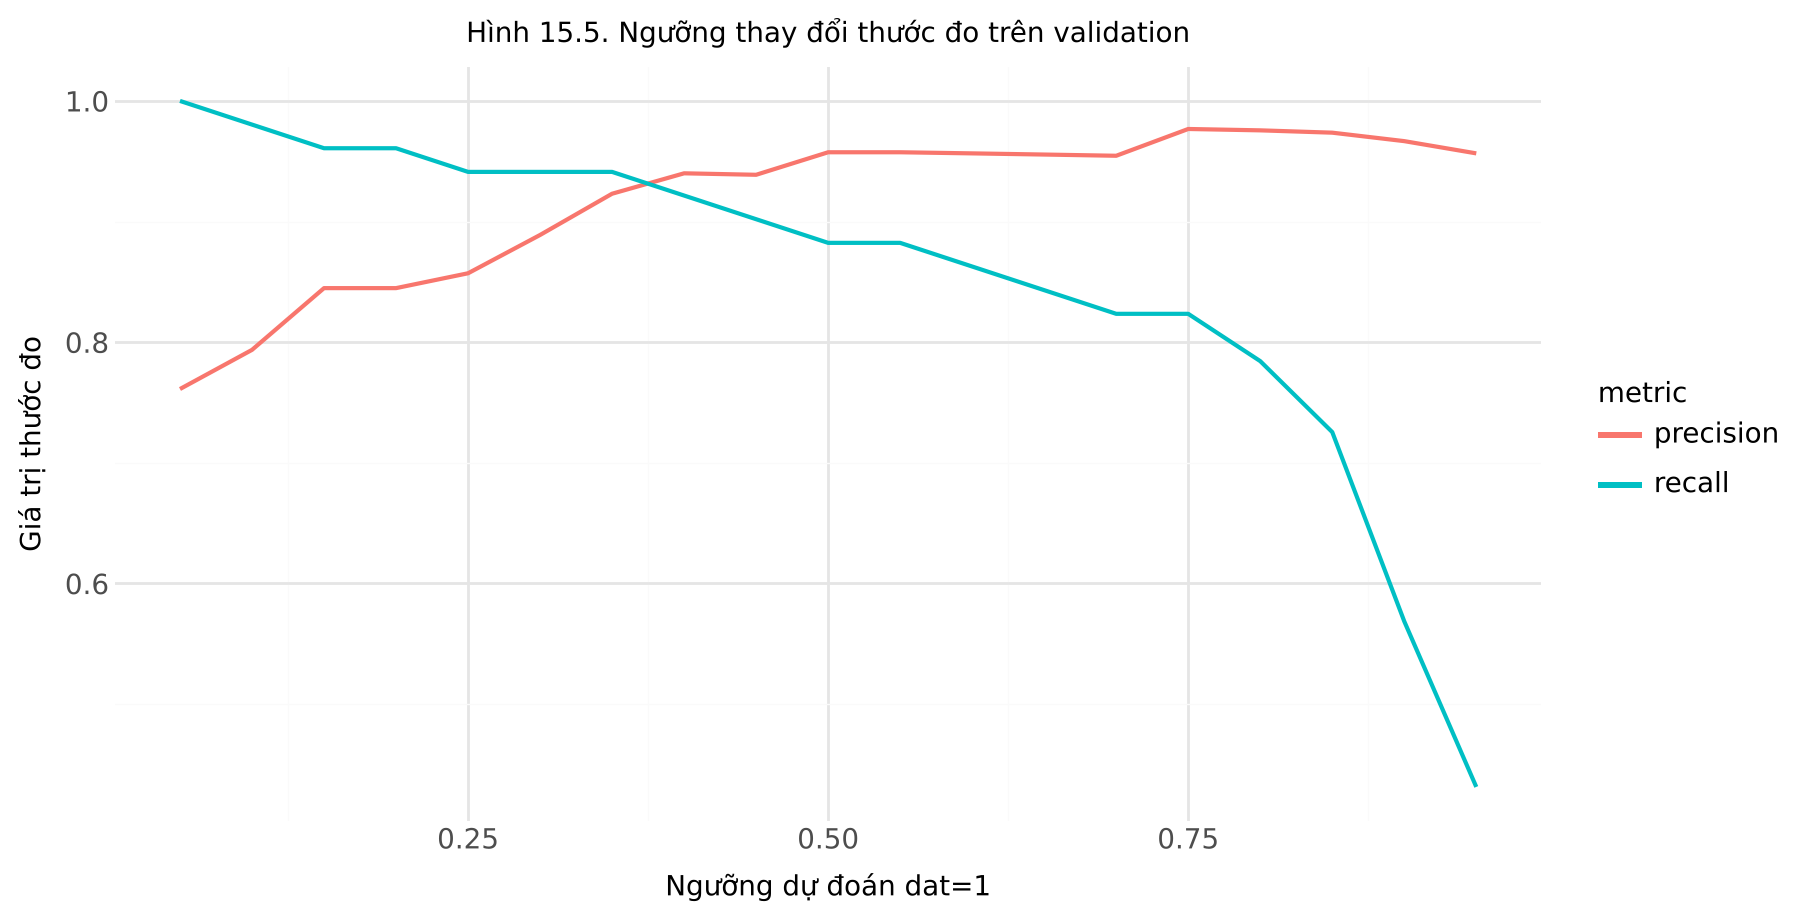

In [12]:
p = (ggplot(threshold_long, aes(x='threshold', y='value', color='metric'))
     + geom_line(size=0.85)
     + labs(title='Hình 15.5. Ngưỡng thay đổi thước đo trên validation', x='Ngưỡng dự đoán dat=1', y='Giá trị thước đo')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

**Kết quả.** $F_1$ lớn nhất (0,932) ở ngưỡng **0,35**, với 48 TP, 3 FN, 4 FP. Ngưỡng 0,5 cho $F_1$ 0,918: ít báo động giả hơn (2 FP) nhưng bỏ sót nhiều hơn (6 FN).

Hạ ngưỡng chỉ thêm ca vào nhóm "báo dương", nên **recall không bao giờ giảm** (trên cùng dữ liệu, cùng quy tắc $\ge$). Precision thì **không nhất thiết** giảm đều: nó tùy những ca vừa được thêm vào là đúng hay sai. Hình của slide cho thấy xu hướng thường gặp, không phải định luật.

Ngưỡng tốt nhất theo $F_1$ chưa chắc là ngưỡng tốt nhất cho quyết định thật, nếu chi phí của FN và FP khác nhau nhiều (Bài tập 4).

**Thử đổi ngưỡng trên validation.** Thêm một ô mới và chạy `classification_metrics(valid.dat, probability_valid, 0.3)`, rồi lần lượt `0.5`, `0.7`. So bốn ô TP, FP, FN, TN giữa ba lần. Nếu muốn đổi tiêu chí chọn ngưỡng (ví dụ ưu tiên recall), hãy đổi **trước** khi đọc kết quả test ở mục 6.

### Bài tập 4 — Tính precision/recall và chọn mô hình

Hai mô hình phát hiện sản phẩm lỗi (ma trận nhầm lẫn trên tập kiểm tra; lớp 1 = **lỗi**):

| Mô hình | TP | FN | FP | TN |
|---|---|---|---|---|
| A | 20 | 30 | 2 | 48 |
| B | 42 | 8 | 20 | 30 |

(a) Tính precision và recall cho mỗi mô hình. (b) Nếu chi phí bỏ sót lỗi (FN) cao hơn nhiều so với báo động giả (FP), nên chọn mô hình nào? Vì sao?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*(a)*

| | Precision | Recall |
|---|---|---|
| A | $20/22\approx0{,}91$ | $20/50=0{,}40$ |
| B | $42/62\approx0{,}68$ | $42/50=0{,}84$ |

A rất "cẩn thận" (khi báo lỗi thì gần như đúng) nhưng bỏ sót 60% sản phẩm lỗi. B bắt được 84% sản phẩm lỗi nhưng cứ 3 lần báo thì khoảng 1 lần báo nhầm.

*(b)* Chọn **B**: recall 0,84 so với 0,40, tức chỉ bỏ sót 8 thay vì 30 sản phẩm lỗi. Khi FN đắt, recall quan trọng hơn precision hay accuracy.

*Làm rõ bằng chi phí.* Với chi phí mỗi FN là $c_{FN}$, mỗi FP là $c_{FP}$: chi phí A $=30c_{FN}+2c_{FP}$, chi phí B $=8c_{FN}+20c_{FP}$. B rẻ hơn khi $22c_{FN}>18c_{FP}$, tức chỉ cần $c_{FN}>0{,}82\, c_{FP}$. Ô dưới thử $c_{FN}=5$, $c_{FP}=1$.

Nếu hai ma trận này được dùng để **chọn** giữa A và B, thì tập đó đóng vai validation; muốn báo hiệu quả của mô hình đã chọn cần một tập test mới.

</details>

In [13]:
exercise4=pd.DataFrame({'model':['A','B'],'TP':[20,42],'FN':[30,8],'FP':[2,20],'TN':[48,30]})
exercise4['precision']=exercise4.TP/(exercise4.TP+exercise4.FP)
exercise4['recall']=exercise4.TP/(exercise4.TP+exercise4.FN)
exercise4['F1']=2*exercise4.TP/(2*exercise4.TP+exercise4.FP+exercise4.FN)
cost_fn=5;cost_fp=1  # Giả định chi phí minh họa,không phải quy tắc triển khai
exercise4['cost']=cost_fn*exercise4.FN+cost_fp*exercise4.FP
display(exercise4)
# Bài3 và baseline2% lỗi
print('Bài3:',12/16,6/8,6/8,12/(12+2+2))
print('Baseline2% lỗi: accuracy=',.98,'recall=',0)

,model,TP,FN,FP,TN,precision,recall,F1,cost
0,A,20,30,2,48,0.90909,0.40,0.55556,152
1,B,42,8,20,30,0.67742,0.84,0.75000,60


Bài3: 0.75 0.75 0.75 0.75
Baseline2% lỗi: accuracy= 0.98 recall= 0


Với $c_{FN}=5$, $c_{FP}=1$: chi phí A $=152$, B $=60$. $F_1$ cũng nghiêng về B (0,75 so với 0,56).

**Thử đổi.** Đặt `cost_fn = 0.5` (bỏ sót rẻ hơn báo nhầm, ví dụ khi mỗi lần báo phải dừng cả dây chuyền) rồi chạy lại: A thành rẻ hơn. Lựa chọn mô hình phụ thuộc vào hậu quả của từng loại sai lầm, không chỉ vào tên một thước đo.

### Quá khớp cũng xảy ra trong phân loại

Mô hình phân loại phức tạp cũng có thể quá khớp: accuracy hay recall rất cao trên tập huấn luyện nhưng tụt mạnh trên dữ liệu mới. Vì vậy mọi thước đo phân loại cũng phải đo trên tập kiểm tra hoặc bằng kiểm định chéo, giống như với hồi quy.

<a id="muc-6"></a>

## 6. Báo cáo cuối: xác suất, nhãn và calibration

### Calibration (độ hiệu chỉnh)

Với hồi quy logistic không dùng $R^2$ như hồi quy tuyến tính. Một câu hỏi tự nhiên là: **xác suất dự đoán có khớp với tần suất thực tế không?** Nếu mô hình nói "80%" cho một nhóm sản phẩm, thì trong nhóm đó có khoảng 80% đạt không?

Cách làm:

1. Gộp các quan sát có xác suất dự đoán gần nhau vào một nhóm (ví dụ 5 khoảng: 0–0,2; 0,2–0,4; ...).
2. Trong mỗi nhóm, tính xác suất dự đoán **trung bình** và tỉ lệ đạt **thực tế**.
3. Vẽ điểm (dự đoán trung bình, tỉ lệ thực tế). Nếu mô hình hiệu chỉnh tốt, các điểm nằm gần **đường chéo** $y=x$. Điểm dưới đường chéo: mô hình dự đoán quá cao ở vùng đó; trên đường chéo: quá thấp.

Luôn ghi **số quan sát** mỗi nhóm: nhóm ít quan sát cho tỉ lệ dao động mạnh.

**Calibration và precision/recall đo hai thứ khác nhau.** Precision, recall nói về **nhãn** ở một ngưỡng; calibration nói về **xác suất** trước khi phân ngưỡng. Một mô hình có thể tốt ở mặt này mà chưa tốt ở mặt kia.

### Báo cáo trên test cuối

Mô hình (khớp trên train) và ngưỡng 0,35 (chọn trên validation) đã chốt. Bây giờ mới dùng tập test, đúng một lần, cho cả nhãn và calibration. Không khớp lại, không đổi ngưỡng dựa vào kết quả này. Kết quả nói về dữ liệu từ **cùng** quá trình sinh; khi thiết bị hay quy trình thay đổi, cần đánh giá lại.

In [14]:
probability_test=logit.predict(test).to_numpy()
final_metrics=classification_metrics(test.dat,probability_test,selected_threshold)
print('Test cuối,ngưỡng đã chốt từ validation:',final_metrics)
print('Ma trận,hàng thực tế0/1,cột dự đoán0/1:')
display(pd.DataFrame([[final_metrics['TN'],final_metrics['FP']],
                      [final_metrics['FN'],final_metrics['TP']]],
                     index=['Thực tế0','Thực tế1'],columns=['Dự đoán0','Dự đoán1']))
calibration=test.assign(probability=probability_test)
calibration['bin']=pd.cut(calibration.probability,np.linspace(0,1,6),include_lowest=True)
calibration_table=calibration.groupby('bin',observed=True).agg(
    predicted=('probability','mean'),observed=('dat','mean'),n=('dat','size')).reset_index()
display(calibration_table)
assert final_metrics['TP']+final_metrics['TN']+final_metrics['FP']+final_metrics['FN']==len(test)

Test cuối,ngưỡng đã chốt từ validation: {'threshold': 0.35, 'TP': 45, 'TN': 43, 'FP': 7, 'FN': 6, 'accuracy': 0.8712871287128713, 'precision': 0.8653846153846154, 'recall': 0.8823529411764706, 'F1': 0.8737864077669902}
Ma trận,hàng thực tế0/1,cột dự đoán0/1:


,Dự đoán0,Dự đoán1
Thực tế0,43,7
Thực tế1,6,45


,bin,predicted,observed,n
0,"(-0.001, 0.2]",0.02610,0.09302,43
1,"(0.2, 0.4]",0.29968,0.28571,7
2,"(0.4, 0.6]",0.44800,0.60000,5
3,"(0.6, 0.8]",0.75029,0.40000,5
4,"(0.8, 1.0]",0.96744,0.97561,41


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** Mỗi dòng của `calibration_table` là một nhóm xác suất. `aes('predicted', 'observed', size='n')`: trục ngang là xác suất dự đoán trung bình, trục đứng là tỉ lệ đạt thực tế, **kích thước chấm** theo số quan sát. `geom_abline(intercept=0, slope=1)` vẽ đường chéo $y=x$; `coord_cartesian` cố định hai trục trong $[0,1]$.

**Đọc hình.** Hai chấm to ở hai đầu (gần 0 và gần 1, mỗi chấm hơn 40 quan sát) nằm sát đường chéo. Ba chấm nhỏ ở giữa (5–7 quan sát) lệch xa hơn, đặc biệt nhóm 0,6–0,8: dự đoán trung bình 0,75 nhưng chỉ 2/5 đạt.

<!-- branch-plot-instructions: end -->

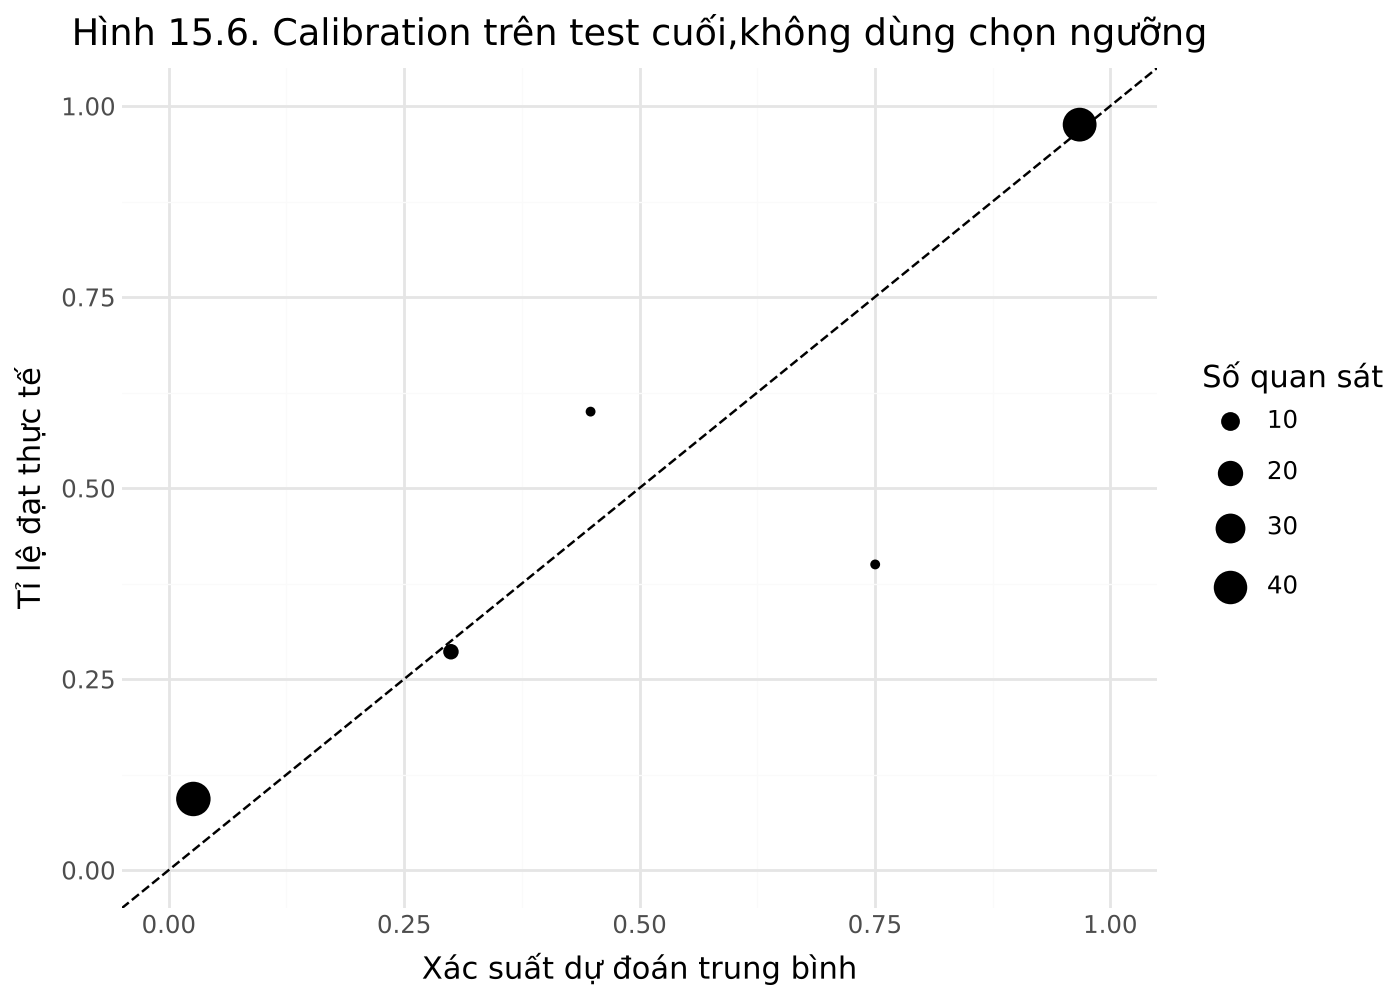

In [15]:
from plotnine import geom_abline
display(ggplot(calibration_table,aes('predicted','observed',size='n'))+geom_point()
    +geom_abline(intercept=0,slope=1,linetype='dashed')
    +coord_cartesian(xlim=(0,1),ylim=(0,1))
    +labs(title='Hình 15.6. Calibration trên test cuối,không dùng chọn ngưỡng',x='Xác suất dự đoán trung bình',y='Tỉ lệ đạt thực tế',size='Số quan sát')
    +theme_minimal()+theme(figure_size=(7,5)))

**Kết quả trên test cuối.** Ở ngưỡng 0,35 đã chốt: 45 TP, 43 TN, 7 FP, 6 FN; accuracy 0,87, precision 0,87, recall 0,88, $F_1$ 0,87. Các con số thấp hơn một chút so với validation ($F_1$ 0,93): đúng như dự đoán ở mục 2, con số trên tập dùng để chọn thường hơi lạc quan.

**Calibration.** Hai nhóm đông nhất nằm sát đường chéo. Nhóm 0,6–0,8 lệch nhiều nhưng chỉ có 5 quan sát: với $n=5$, tỉ lệ thực tế chỉ có thể là 0; 0,2; 0,4; ... nên độ lệch này có thể chỉ do ngẫu nhiên. Muốn kết luận về calibration ở vùng giữa cần nhiều dữ liệu hơn.

## Tóm tắt và lỗi hay gặp

| Ý chính | Lỗi hay gặp |
|---|---|
| Mục tiêu dự đoán là sai số **ngoài mẫu** thấp. | Chọn mô hình vì sai số huấn luyện nhỏ hay $R^2$ cao. |
| Thiếu khớp: sai số cao ở cả hai tập. Quá khớp: train rất thấp, ngoài mẫu cao. | Nhìn khoảng cách train–test mà quên mức sai số. |
| Train để khớp, validation (hoặc CV) để chọn, test cuối để báo cáo, đúng một lần. | Dùng tập test để chọn rồi báo con số của nó như đánh giá độc lập. |
| $k$-fold: mỗi fold làm validation đúng một lần; mọi bước học từ dữ liệu làm trong từng fold. | Chuẩn hóa hay chọn biến trên toàn bộ dữ liệu trước khi chia fold. |
| Logistic: $\hat p=1/(1+e^{-\eta})$; $\eta$ là log-odds. | Dùng hồi quy tuyến tính cho xác suất (ra ngoài $[0,1]$). |
| Tăng $x_j$ 1 đơn vị làm odds **nhân** $e^{b_j}$. | “Xác suất tăng $b_j$” hay “tăng $100b_j$%”. |
| Ma trận nhầm lẫn: hàng thực tế, cột dự đoán; TP, TN, FP, FN. | Lẫn FP với FN; quên quy ước lớp 1. |
| Precision = TP/(TP+FP); Recall = TP/(TP+FN); $F_1$ = 2TP/(2TP+FP+FN). | Chỉ báo accuracy khi lớp mất cân bằng. |
| Ngưỡng 0,5 không bắt buộc; chọn theo chi phí sai lầm, trên validation. | Dò ngưỡng trên tập test. |
| Calibration kiểm tra xác suất; precision/recall kiểm tra nhãn. | Nghĩ sigmoid trong $(0,1)$ là xác suất đã đúng. |

## Tự kiểm tra và nối sang buổi tiếp theo

1. Quay về bốn loại khẳng định của Tuần 01: **mô tả** mẫu cần tóm tắt đúng; **tổng quát hóa** cần thiết kế lấy mẫu và đo độ bất định; **nhân quả** cần phản thực và thiết kế; **dự đoán** cần đánh giá trên dữ liệu chưa tham gia khớp hay chọn. Chọn một output trong bài và nói nó hỗ trợ loại khẳng định nào.
2. Một mô hình có $R^2=0{,}99$ trên tập huấn luyện. Bạn cần thêm thông tin gì trước khi tin nó dự đoán tốt?
3. Hệ số logistic của một biến là $-1{,}2$. Odds thay đổi thế nào khi biến đó tăng 1 đơn vị?
4. Phát hiện gian lận thẻ tín dụng: 0,1% giao dịch là gian lận. Mô hình A có accuracy 99,9%, mô hình B có accuracy 97% và recall 0,85. Mô hình nào có thể là “luôn báo không gian lận”?

<details><summary>Gợi ý đáp án</summary>

2. Sai số trên dữ liệu chưa thấy (tập test hoặc kiểm định chéo), số biến so với số quan sát, và quy trình chọn mô hình có dùng tập test không.
3. Nhân với $e^{-1{,}2}\approx0{,}30$, tức giảm khoảng 70%.
4. A: mô hình luôn báo “không gian lận” có accuracy đúng 99,9% và recall 0.

</details>

**Buổi sau.** Đây là buổi cuối của học phần. Khi tự làm một bài toán mới, hãy ghi rõ dữ liệu nào dùng để **khớp**, dữ liệu nào dùng để **chọn**, dữ liệu nào dùng để **báo cáo cuối**. Nếu ranh giới giữa ba phần thay đổi, cách diễn giải kết quả cũng phải thay đổi theo.

## Nguồn học liệu

- Slide của học phần: `week15.pdf`; số trang được ghi trong metadata `source_pages` của từng ô.
- Đề cương UET.MAT1052: mục và chuẩn đầu ra của tuần tương ứng.
- STAT 20 bản dịch tiếng Việt: mục 7.4–7.5. Các hình tham khảo được nhúng thẳng vào notebook.
- Dữ liệu và cách chuyển đổi: `datasets/W09_W15_SOURCE_MANIFEST.json` và [hướng dẫn tuần 09–15](./README_W09_W15.md). Dữ liệu OpenIntro lấy từ [kho dữ liệu của nhà xuất bản](https://www.openintro.org/data/).